In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
import re
from itertools import combinations
from scipy.stats import ttest_ind
from matplotlib.lines import Line2D

In [2]:
# HELPER FUNCTIONS
# for time 
def time_to_seconds(t):
    if pd.isna(t):
        return None
    # make sure it's a string
    t = str(t).strip()
    # parse HH:MM:SS (or MM:SS) to seconds
    return pd.to_timedelta(t).total_seconds()

# blank correction
def blank_correction(df: pd.DataFrame, blank_wells: list[str]) -> pd.DataFrame:
    blank_series = df[blank_wells].mean(axis=1)
    return df.drop(columns=blank_wells).sub(blank_series, axis=0)

# compute volumetric activity
def compute_activity_U_mL(
    df: pd.DataFrame,
    volume,
    *,
    epsilon: float = 6.22,
    r_mm: float = 6.9 / 2,
    V_uL: float = 200,
    Ve_uL: float = 10,
    min_points: int = 2,
) -> pd.Series:
    """
    volume:
        - float → single volume for all samples
        - dict  → {volume_value: (sample_names, ...)}
    """

    x = df.index.to_numpy(float)

    # path length (cm)
    l_cm = (V_uL / (math.pi * r_mm**2)) / 10

    # constant part (everything except slope and volume)
    k_base = (V_uL * 60) / (epsilon * l_cm * Ve_uL)

    # --- resolve per-column volume ---
    if isinstance(volume, dict):
        volume_map = {}
        for vol, names in volume.items():
            for name in names:
                volume_map[name] = vol
    else:
        volume_map = None  # scalar case

    out = {}

    for col in df.columns:
        y = df[col].to_numpy(float)
        m = np.isfinite(x) & np.isfinite(y)

        if m.sum() < min_points:
            out[col] = np.nan
            continue

        slope = np.polyfit(x[m], y[m], 1)[0]

        #print(slope)

        # pick correct volume
        vol = volume_map[col] if volume_map is not None else volume

        out[col] = abs(slope) * (k_base / vol)

    return pd.Series(out, name="activity_U_mL")

# function to build useful OD df
def expand_OD_df(df_A, df_B, repeat=3, col2_name="OD"):

    # Keep BOTH well and activity
    col1_df = df_A.reset_index()
    col1_df.columns = ["Well", "Activity"]

    # OD part (skip first row, first 3 cols)
    flat = df_B.iloc[1:, :3].to_numpy().ravel(order="C")
    col2 = np.repeat(flat, repeat)

    if len(col1_df) != len(col2):
        raise ValueError("Length mismatch")

    col1_df[col2_name] = col2

    return col1_df

# normalize activity for OD
def normalize_activity(activity_series, df_OD, od_column="OD", id_col="Well"):

    od_map = df_OD.set_index(id_col)[od_column]

    activity_norm = activity_series / od_map

    return activity_norm.rename("activity_norm")

# pooling
# each biological sample contributes equally to the mean
# the SD is computed across biological samples (not technical replicates)
# n = number of biological samples, not total replicates 
def pooled_over_groups(
    s: pd.Series,
    replicates: int = 3,
    groups_per_pool: int = 3
) -> pd.DataFrame:
    
    if len(s) % replicates != 0:
        raise ValueError("Length of series must be divisible by number of replicates")

    pooled = []
    n_groups = len(s) // replicates

    for g0 in range(0, n_groups, groups_per_pool):
        # Collect biological groups
        block = [
            s.iloc[i * replicates:(i + 1) * replicates]
            for i in range(g0, min(g0 + groups_per_pool, n_groups))
        ]

        # Compute one mean per biological sample
        group_means = np.array(
            [g.mean(skipna=True) for g in block],
            dtype=float
        )

        # Remove NaNs (in case entire group is NaN)
        group_means = group_means[~np.isnan(group_means)]

        # Compute pooled stats at biological level
        if len(group_means) == 0:
            pooled_mean = np.nan
            pooled_sd = np.nan
            pooled_n = 0
        else:
            pooled_mean = group_means.mean()
            pooled_n = len(group_means)
            pooled_sd = (
                group_means.std(ddof=1)
                if pooled_n >= 2 else np.nan
            )

        pooled.append({
            "pool": g0 // groups_per_pool + 1,
            "mean": pooled_mean,
            "std": pooled_sd,
            "n": pooled_n,
        })

    return pd.DataFrame(pooled)

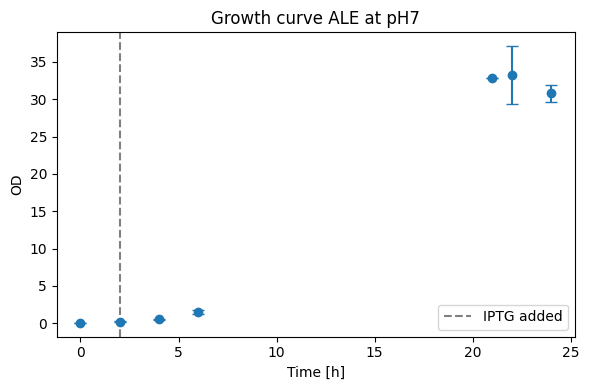

In [3]:
# plot OD
# load OD data
OD_ALE7 = (pd.read_excel('ALE7_OD.xlsx').set_index('time [h]').apply(pd.to_numeric, errors="coerce"))

# calculate mean and std
OD_ALE7_summary = pd.DataFrame({
    'mean_OD': OD_ALE7.mean(axis=1),
    'std_OD': OD_ALE7.std(axis=1)
})

# PLOT
fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(OD_ALE7.index, OD_ALE7_summary['mean_OD'], yerr=OD_ALE7_summary['std_OD'],
            fmt='o', capsize=4)

ax.axvline(x=2, color='0.5', linestyle='--', label='IPTG added')

ax.set_xlabel("Time [h]")
ax.set_ylabel("OD")
ax.legend()
ax.set_title('Growth curve ALE at pH7')

plt.tight_layout()
plt.show()

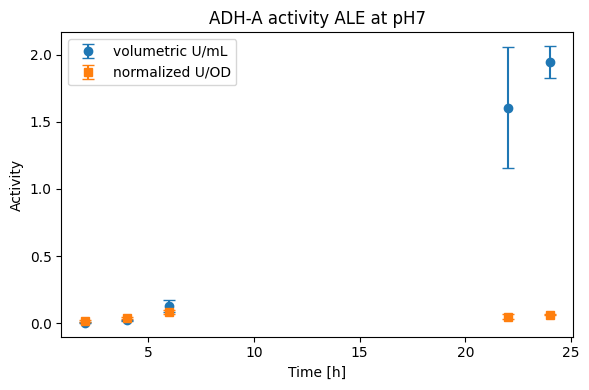

In [4]:
# ADH-A ACTIVITY

# calculate activity values
ADHA_ALE7 = pd.read_csv('ALE7_20L_140526.CSV', delimiter=',', skiprows=5)

ADHA_ALE7 = ADHA_ALE7.iloc[1:-1, 1:]
ADHA_ALE7.iloc[:, 0] = ADHA_ALE7.iloc[:, 0].apply(time_to_seconds)
ADHA_ALE7 = ADHA_ALE7.set_index(ADHA_ALE7.columns[0]).rename_axis("Time [s]")
ADHA_ALE7 = ADHA_ALE7.apply(pd.to_numeric, errors="coerce")

# blank correction
ADHA_ALE7_corr = blank_correction(ADHA_ALE7, ['A01', 'A02'])

# make small overview plots
"""
ycols = ADHA_ALE7_corr.columns
groups = [ycols[i:i+3] for i in range(0, len(ycols), 3)]

for i in range(0, len(groups), 3):
    fig, axes = plt.subplots(1, 3, figsize=(8, 2), sharex=True, sharey=True)

    for ax, cols in zip(axes, groups[i:i+3]):
        ADHA_ALE7_corr[cols].plot(ax=ax, legend=False, alpha=0.8)

        ax.set_title(", ".join(cols), fontsize=9)
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Signal")
        ax.legend()

    plt.tight_layout()
    plt.show()
"""
# limit the time to 25x10s
ADHA_ALE7_corr = ADHA_ALE7_corr.loc[ADHA_ALE7_corr.index <= 250]

# volumetric activity
volumes = {0.660: ('B01', 'B02', 'B03'),
           0.420: ('B04', 'B05', 'B06'),
           0.500: ('B07', 'B08', 'B09'),
           0.208: ('C01', 'C02', 'C03'),
           0.167: ('C04', 'C05', 'C06'),
           0.198: ('C07', 'C08', 'C09'),
           0.078: ('D01', 'D02', 'D03'),
           0.055: ('D04', 'D05', 'D06'),
           0.067: ('D07', 'D08', 'D09'),
           0.0034: ('E01', 'E02', 'E03', 'F01', 'F02', 'F03', 'F07', 'F08', 'F09'),
           0.0027: ('E04', 'E05', 'E06'),
           0.0030: ('E07', 'E08', 'E09'),
           0.0031: ('F04', 'F05', 'F06')}

act_ALE7_vol  = compute_activity_U_mL(ADHA_ALE7_corr, volume=volumes)

# drop unwanted samples
#act_ALE7_vol['F08'] = np.nan

# normalize activity for OD
OD_ALE7_short = OD_ALE7.drop(index=21)

OD_ALE7_long = expand_OD_df(act_ALE7_vol, OD_ALE7_short, repeat=3)

act_ALE7_norm = normalize_activity(act_ALE7_vol, OD_ALE7_long, od_column="OD", id_col="Well")

# summarize
vol = pooled_over_groups(act_ALE7_vol).add_prefix("vol_")
norm = pooled_over_groups(act_ALE7_norm).add_prefix("norm_")

act_ALE7_summary = vol.merge(norm, left_on="vol_pool", right_on="norm_pool", how="outer")

# PLOT
x = [2, 4, 6, 22, 24]
fig, ax = plt.subplots(figsize=(6, 4))

# volumetric
ax.errorbar(x, act_ALE7_summary['vol_mean'], yerr=act_ALE7_summary['vol_std'],
            fmt='o', capsize=4, label='volumetric U/mL')

# normalized
ax.errorbar(x, act_ALE7_summary['norm_mean'], yerr=act_ALE7_summary['norm_std'],
            fmt='s', capsize=4, label='normalized U/OD')

ax.set_xlabel("Time [h]")
ax.set_ylabel("Activity")
ax.legend()
ax.set_title('ADH-A activity ALE at pH7')

plt.tight_layout()
plt.show()

In [5]:
# EXPORT results
OD_ALE7_summary.to_parquet('OD_ALE7_20L.parquet')
act_ALE7_summary.to_parquet('act_ALE7_20L.parquet')

#act_ALE7_vol.to_frame(name=act_ALE7_vol.name or "value").to_parquet("act_ALE7_vol.parquet")
#act_ALE7_norm.to_frame(name=act_ALE7_norm.name or "value").to_parquet("act_ALE7_norm.parquet")

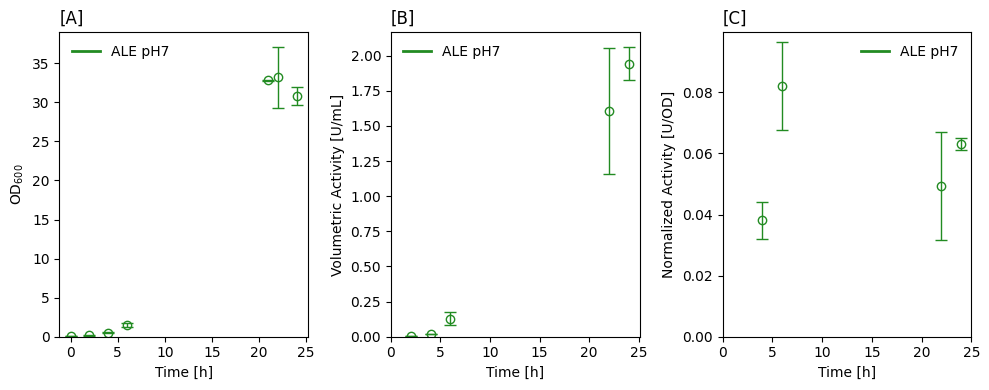

In [9]:
# time points for activity plots
x = [2, 4, 6, 22, 24]
x_norm = [4, 6, 22, 24]
x_ticks = [0, 5, 10, 15, 20, 25]

# ---------------- Figure layout ----------------
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

ax_A = axs[0]   # volumetric over time
ax_B = axs[1]   # normalized over time
ax_C = axs[2]   # OD over time
#ax_empty = axs[1, 1]
#ax_empty.axis("off")

# ---------------- Common styling ----------------
legend_elements = [
    Line2D([0], [0], color='forestgreen', lw=2, label='ALE pH7')
]

# ---------------- A: OD over time ----------------
ax_A.errorbar(OD_ALE7_summary.index, OD_ALE7_summary["mean_OD"], yerr=OD_ALE7_summary["std_OD"],
              fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen',
              capsize=4, elinewidth=1, zorder=1)

ax_A.set_xlabel("Time [h]")
ax_A.set_xticks(x_ticks)
ax_A.set_xticklabels(x_ticks)
ax_A.set_ylabel("OD$_{600}$")
ax_A.set_title('[A]', loc='left')
ax_A.set_ylim(bottom=0)
ax_A.legend(handles=legend_elements, frameon=False)

# ---------------- B: volumetric activity over time ----------------
ax_B.errorbar(x, act_ALE7_summary['vol_mean'], yerr=act_ALE7_summary['vol_std'],
              fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen', capsize=4, elinewidth=1)

ax_B.set_xlabel("Time [h]")
ax_B.set_xticks(x_ticks)
ax_B.set_xticklabels(x_ticks)
ax_B.set_ylabel("Volumetric Activity [U/mL]")
ax_B.set_title('[B]', loc='left')
ax_B.set_ylim(bottom=0)
ax_B.legend(handles=legend_elements, frameon=False)

# ---------------- C: normalized activity over time ----------------
ax_C.errorbar(x_norm, act_ALE7_summary['norm_mean'][1:], yerr=act_ALE7_summary['norm_std'][1:],
              fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen', capsize=4, elinewidth=1)

ax_C.set_xlabel("Time [h]")
ax_C.set_xticks(x_ticks)
ax_C.set_xticklabels(x_ticks)
ax_C.set_ylabel("Normalized Activity [U/OD]")
ax_C.set_title('[C]', loc='left')
ax_C.set_ylim(bottom=0)
ax_C.legend(handles=legend_elements, frameon=False)

plt.tight_layout()

#plt.savefig("batch_20L.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# separate results for VOL activity for biological repeats
groups = (range(len(act_ALE7_vol)))
group_id = pd.Series(groups, index=act_ALE7_vol.index) // 3

mean_3 = act_ALE7_vol.groupby(group_id).mean()
std_3  = act_ALE7_vol.groupby(group_id).std()

result = pd.DataFrame({
    "mean_3": mean_3,
    "std_3": std_3
})

print(result)